# 01 - Exploratory data analysis

Exploration only (no preprocessing, no models). Reads `data/processed/{train,val,test}.csv` and does not modify them.
Each section has code, a table or plot, and a short takeaway.

In [1]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import emoji
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

SPLITS = ["train", "val", "test"]
LABELS = ["negative", "neutral", "positive"]
LABEL_COLORS = {"negative": "#d1495b", "neutral": "#8d99ae", "positive": "#2e9e6b"}

FIG_DIR = Path("figures")          # the 3 most useful plots are saved here
FIG_DIR.mkdir(exist_ok=True)

# dtype=str + keep_default_na=False so words like "nan" or "None" are not turned into missing values
data = {s: pd.read_csv(f"../data/processed/{s}.csv", dtype=str, keep_default_na=False) for s in SPLITS}

# Extra columns used in several sections: token list, tag list, token count
for s in SPLITS:
    df = data[s]
    df["tokens"] = df["text"].str.split()
    df["tags"] = df["lang_tags"].str.split()
    df["n_tokens"] = df["tokens"].str.len()
    assert (df["tokens"].str.len() == df["tags"].str.len()).all()   # tokens and tags must line up

train, val, test = data["train"], data["val"], data["test"]
print({s: data[s].shape for s in SPLITS})

{'train': (14000, 7), 'val': (3000, 7), 'test': (3000, 7)}


In [2]:
# ---- Helper: find URLs. In this data a URL is split into tokens, e.g.
#      "https // t . co / AbC123xyz"  or  "https // t co / AbC123xyz"  or  "https // tco / AbC123xyz"
URL_PIECES = {"//", "t", "co", "tco", ".", "/", ":"}      # tokens that can appear inside the domain part

def find_urls(tokens):
    """Return a list of (start, end, shape) for every URL in a token list.
    'shape' is the URL with its random id replaced by xxx (or '...' when the URL was cut off)."""
    found = []
    i = 0
    while i < len(tokens):
        if tokens[i].lower() in ("http", "https"):
            j = i + 1
            while j < len(tokens) and tokens[j] in URL_PIECES:      # walk through the domain pieces
                j += 1
            shape = tokens[i:j]
            # After the last "/" comes the random id; a cut-off URL has "…" there instead
            if j < len(tokens) and tokens[j - 1] == "/" and re.fullmatch(r"[A-Za-z0-9]+", tokens[j]):
                shape = shape + ["xxx"]
                j += 1
            elif j < len(tokens) and tokens[j].startswith("…"):
                shape = shape + ["…"]
                j += 1
            found.append((i, j, " ".join(shape)))
            i = j
        else:
            i += 1
    return found

def skip_indices(tokens):
    """Token positions that are NOT real words: URL pieces and the user name right after a split '@'."""
    skip = set()
    for start, end, _ in find_urls(tokens):
        skip.update(range(start, end))
    for k, tok in enumerate(tokens[:-1]):
        if tok == "@":
            skip.add(k + 1)
    return skip

# quick self-test on a made-up tweet
print(find_urls("wow nice https // t . co / AbC123xyz bye".split()))

[(2, 9, 'https // t . co / xxx')]


## 1. Overview: shape and label balance

In [3]:
rows = []
for s in SPLITS:
    counts = data[s]["label"].value_counts()
    row = {"split": s, "rows": len(data[s])}
    for lab in LABELS:
        row[f"{lab} n"] = counts.get(lab, 0)
    for lab in LABELS:
        row[f"{lab} %"] = round(100 * counts.get(lab, 0) / len(data[s]), 1)
    rows.append(row)
overview = pd.DataFrame(rows).set_index("split")
overview

,rows,negative n,neutral n,positive n,negative %,neutral %,positive %
split,,,,,,,
train,14000,4102,5264,4634,29.3,37.6,33.1
val,3000,890,1128,982,29.7,37.6,32.7
test,3000,900,1100,1000,30.0,36.7,33.3


**Takeaway**

All three splits have almost the same label mix: about 37% neutral, 33% positive, 30% negative. No class is tiny, so no resampling is needed.
A model that always says 'neutral' would already score about 37% accuracy, so report macro-F1 and a confusion matrix, not accuracy alone.

## 2. Tweet length in tokens

Per split


,tweets,mean,median,p95,p99,max
split,,,,,,
train,14000,26.1,28.0,34.0,37.0,56
val,3000,26.2,28.0,34.0,36.0,44
test,3000,26.1,28.0,34.0,36.0,41


Per class (train only)


,tweets,mean,median,p95,p99,max
label,,,,,,
negative,4102,27.0,29.0,34.0,36.0,42
neutral,5264,25.8,28.0,34.0,37.0,56
positive,4634,25.7,27.0,34.0,36.0,45


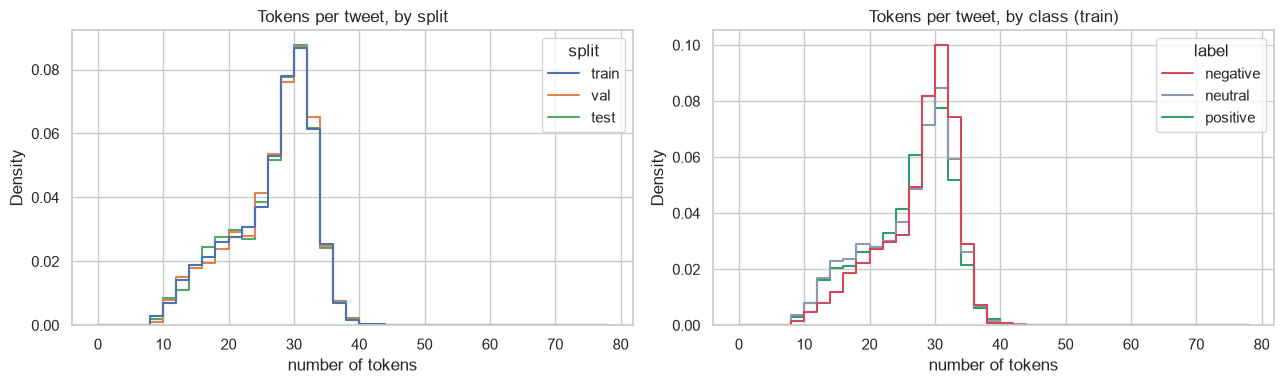

Train: a max length of 34 tokens covers 95% of tweets, 37 tokens covers 99%  (longest tweet: 56 tokens)


In [4]:
def length_table(df, by):
    g = df.groupby(by)["n_tokens"]
    return pd.DataFrame({
        "tweets": g.size(), "mean": g.mean().round(1), "median": g.median(),
        "p95": g.quantile(0.95).round(1), "p99": g.quantile(0.99).round(1), "max": g.max(),
    })

all_df = pd.concat([data[s].assign(split=s) for s in SPLITS])
print("Per split"); display(length_table(all_df, "split").loc[SPLITS])
print("Per class (train only)"); display(length_table(train, "label").loc[LABELS])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(0, 80, 2)
sns.histplot(data=all_df, x="n_tokens", hue="split", hue_order=SPLITS, bins=bins, stat="density",
             common_norm=False, element="step", fill=False, ax=axes[0])
axes[0].set_title("Tokens per tweet, by split")
sns.histplot(data=train, x="n_tokens", hue="label", hue_order=LABELS, palette=LABEL_COLORS, bins=bins,
             stat="density", common_norm=False, element="step", fill=False, ax=axes[1])
axes[1].set_title("Tokens per tweet, by class (train)")
for ax in axes:
    ax.set_xlabel("number of tokens")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_token_length.png", dpi=150, bbox_inches="tight")
plt.show()

p95, p99 = train["n_tokens"].quantile(0.95), train["n_tokens"].quantile(0.99)
print(f"Train: a max length of {int(np.ceil(p95))} tokens covers 95% of tweets, "
      f"{int(np.ceil(p99))} tokens covers 99%  (longest tweet: {train['n_tokens'].max()} tokens)")

**Takeaway**

The typical tweet has 28 tokens. In train, 34 tokens cover 95% of tweets and 37 tokens cover 99% (the longest has 56). Splits and classes look alike, and negative tweets are slightly longer (mean 27.0 vs 25.7 for positive).
For the BiLSTM a max length of 40 words covers more than 99% of tweets. Transformers count sub-word pieces, which are more than words, so check with the real tokenizers before fixing their max length (64 is a sensible first guess).

## 3. Language-tag mix per sentiment class

> **Caution:** the language tags are noisy, so treat these numbers as rough hints, not ground truth.
> For example Devanagari words are tagged `O`, and the same word can be tagged differently depending on case
> (`HIT` tagged `Hin` but `hit` tagged `Eng`). The cells below measure this noise.

All tags in train: {'Hin': 169893, 'Eng': 121412, 'O': 73716, 'EMT': 520}
19.7% of train tokens are URL pieces or @user names
Tag share (%), ALL tokens:


tag_group,Hin,Eng,O,EMT
label,,,,
negative,54.1,26.7,19.1,0.1
neutral,45.4,33.6,20.9,0.2
positive,40.6,38.8,20.4,0.2


Tag share (%), real words only (URL pieces and @user names removed) - used in the plot:


tag_group,Hin,Eng,O,EMT
label,,,,
negative,63.5,20.0,16.3,0.1
neutral,51.8,29.0,18.9,0.2
positive,45.5,35.9,18.3,0.2


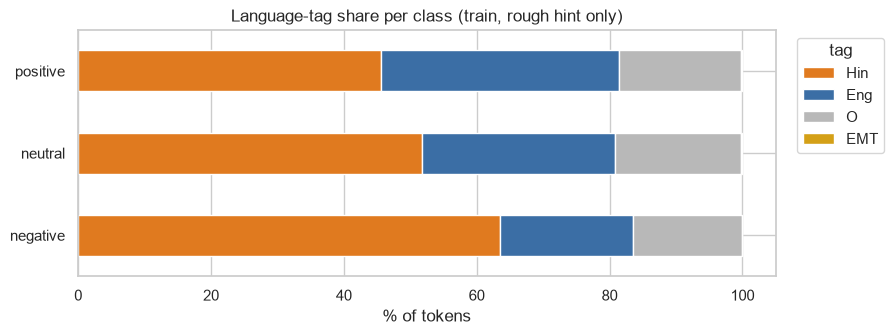

In [5]:
# One row per token, so we can count tags per class
# is_word = False for URL pieces ("https // t . co /") and user names after "@": those tokens are not
# real language, and the dataset tags them as Eng/O, which would distort the language mix.
tok_rows = []
for label, tokens, tags in zip(train["label"], train["tokens"], train["tags"]):
    skip = skip_indices(tokens)
    for k, (tok, tag) in enumerate(zip(tokens, tags)):
        tok_rows.append((label, tok, tag, k not in skip))
tok_df = pd.DataFrame(tok_rows, columns=["label", "token", "tag", "is_word"])

print("All tags in train:", {k: int(v) for k, v in tok_df["tag"].value_counts().items()})
print(f"{100 * (~tok_df['is_word']).mean():.1f}% of train tokens are URL pieces or @user names")
KEEP = ["Hin", "Eng", "O", "EMT"]
tok_df["tag_group"] = tok_df["tag"].where(tok_df["tag"].isin(KEEP), "other")

def tag_mix(d):
    m = pd.crosstab(d["label"], d["tag_group"], normalize="index").loc[LABELS]
    return m[[c for c in KEEP + ["other"] if c in m.columns]]

print("Tag share (%), ALL tokens:"); display((tag_mix(tok_df) * 100).round(1))
mix = tag_mix(tok_df[tok_df["is_word"]])
print("Tag share (%), real words only (URL pieces and @user names removed) - used in the plot:")
display((mix * 100).round(1))

tag_colors = {"Hin": "#e07a1f", "Eng": "#3b6ea5", "O": "#b8b8b8", "EMT": "#d4a017", "other": "#7a5195"}
ax = (mix * 100).plot(kind="barh", stacked=True, figsize=(9, 3.2), color=[tag_colors[c] for c in mix.columns])
ax.set_xlabel("% of tokens"); ax.set_ylabel(""); ax.set_title("Language-tag share per class (train, rough hint only)")
ax.legend(title="tag", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig(FIG_DIR / "fig2_language_mix.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Noise check 1: how are Devanagari tokens tagged?
has_dev = tok_df["token"].str.contains(r"[\u0900-\u097F]")
print("Devanagari tokens by tag:", {k: int(v) for k, v in tok_df.loc[has_dev, "tag"].value_counts().items()})

# Noise check 2: same word, different tags. Lowercased words that are tagged both Hin and Eng.
both = (tok_df[tok_df["tag"].isin(["Hin", "Eng"]) & tok_df["is_word"]]
        .assign(word=lambda d: d["token"].str.lower())
        .groupby(["word", "tag"]).size().unstack(fill_value=0))
both["minority"] = both[["Hin", "Eng"]].min(axis=1)
print("Lowercased words tagged BOTH Hin and Eng:", int((both["minority"] > 0).sum()), "of", len(both))
display(both.sort_values("minority", ascending=False).head(10))

# Noise check 3: the same spelling in different case
for w in ["HIT", "hit", "Hit"]:
    print(f"{w!r}:", {k: int(v) for k, v in tok_df.loc[tok_df["token"] == w, "tag"].value_counts().items()})

Devanagari tokens by tag: {'O': 214}


Lowercased words tagged BOTH Hin and Eng: 4474 of 31182


tag,Eng,Hin,minority
word,,,
to,1641,1575,1575
you,1177,837,837
i,913,812,812
is,1352,546,546
me,395,1636,395
rt,1869,393,393
k,379,1171,379
bjp,379,339,339
or,313,407,313


'HIT': {'Hin': 1}
'hit': {'Hin': 23, 'Eng': 20}
'Hit': {'Hin': 7, 'Eng': 2}


**Takeaway**

Among real words (URL pieces and @names removed), negative tweets are 63.5% Hindi-tagged and 20% English-tagged, while positive tweets are 45.5% Hindi and 36% English. So English-heavy tweets lean positive, but this is only a rough hint.
The tags are noisy: all 214 Devanagari tokens are tagged O, 4,474 of 31,182 word types get both Hin and Eng tags (e.g. 'to', 'me'), and 'hit' is tagged Hin 23 times and Eng 20 times. Do not trust the tags as exact features.

## 4. Emoji

% of tweets with at least one emoji


,train,val,test
label,,,
negative,12.4,10.3,13.1
neutral,19.1,18.8,19.1
positive,25.1,26.8,27.0
ALL,19.1,18.9,19.9


,negative,neutral,positive
1,😂 509,😂 601,😂 284
2,🤣 133,🙏 131,🙏 230
3,😭 30,🤣 128,😍 186
4,😡 27,😭 88,❤️ 158
5,😠 23,😍 81,❤ 147
6,🙄 22,🌹 54,😘 122
7,🙏 20,😘 48,🇮🇳 114
8,🤔 20,❤ 42,😭 100
9,👏 18,❤️ 38,🎂 82
10,😁 17,😊 37,💕 78


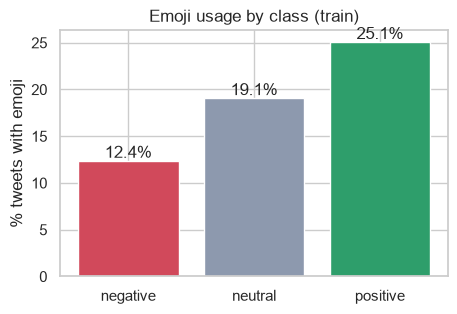

In [7]:
# list of emoji in each tweet (emoji.emoji_list finds every emoji, including flags and skin tones)
for s in SPLITS:
    data[s]["emojis"] = data[s]["text"].apply(lambda t: [e["emoji"] for e in emoji.emoji_list(t)])
    data[s]["has_emoji"] = data[s]["emojis"].str.len() > 0

share = pd.DataFrame({s: (data[s].groupby("label")["has_emoji"].mean().loc[LABELS] * 100).round(1) for s in SPLITS})
share.loc["ALL"] = [round(data[s]["has_emoji"].mean() * 100, 1) for s in SPLITS]
print("% of tweets with at least one emoji"); display(share)

# Top 15 emoji per class (train): each cell is "emoji  count"
top = {}
for lab in LABELS:
    counter = Counter(e for lst in train.loc[train["label"] == lab, "emojis"] for e in lst)
    top[lab] = [f"{e}  {n}" for e, n in counter.most_common(15)]
display(pd.DataFrame(top, index=range(1, 16)))

fig, ax = plt.subplots(figsize=(5, 3.2))
vals = share.loc[LABELS, "train"]
ax.bar(LABELS, vals, color=[LABEL_COLORS[l] for l in LABELS])
for k, v in enumerate(vals):
    ax.text(k, v + 0.3, f"{v}%", ha="center")
ax.set_ylabel("% tweets with emoji"); ax.set_title("Emoji usage by class (train)")
plt.savefig(FIG_DIR / "fig3_emoji_share.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway**

About 19% of tweets contain an emoji, and the share rises from negative (12%) to neutral (19%) to positive (25%), in every split. So emoji carry signal and should be kept.
But 😂 is the top emoji in ALL classes (509 times in negative), so it is not a clean 'positive' sign. Anger emoji (😡 😠 🙄) appear only in the negative top-15; hearts, 😍 and 🎂 rank much higher in positive. Also ❤ and ❤️ are counted as two different emoji, and emoji written together ('😔😔') sit in ONE token.

## 5. Mentions, hashtags and URLs

In [8]:
def share_of(df, test_fn):
    return round(100 * df["text"].apply(test_fn).mean(), 1)

has_split_mention = lambda t: bool(re.search(r"(^| )@ \S", t))                     # "@ name"
has_joined_mention = lambda t: bool(re.search(r"(^| )@\S", t))                       # "@name" (not split)
has_hashtag = lambda t: bool(re.search(r"(^| )# \S", t))
starts_rt = lambda t: t.startswith("RT @")
has_url = lambda t: len(find_urls(t.split())) > 0

summary = pd.DataFrame({
    s: {"split mention '@ name'": share_of(data[s], has_split_mention),
        "joined mention '@name'": share_of(data[s], has_joined_mention),
        "mention with underscore '@ a _ b'": share_of(data[s], lambda t: bool(re.search(r"@ \S+ _ \S+", t))),
        "split hashtag '# word'": share_of(data[s], has_hashtag),
        "starts with 'RT @'": share_of(data[s], starts_rt),
        "contains URL": share_of(data[s], has_url)}
    for s in SPLITS})
print("% of tweets containing each pattern"); display(summary)

# How much of the token stream is this "noise"? (train)
n_all = n_url = n_mention = n_hash = n_urls = 0
for tokens in train["tokens"]:
    n_all += len(tokens)
    urls = find_urls(tokens)
    n_urls += len(urls)
    n_url += sum(end - start for start, end, _ in urls)
    n_mention += sum(1 for t in tokens if t == "@") * 2          # the "@" and the name after it
    n_hash += sum(1 for t in tokens if t == "#")
print(f"Train token stream ({n_all} tokens): URL pieces = {100*n_url/n_all:.1f}%, "
      f"'@ name' pairs = {100*n_mention/n_all:.1f}%, '#' tokens = {100*n_hash/n_all:.1f}%")
print("Average tokens per URL:", round(n_url / n_urls, 1))

print("\nExample mention contexts:")
for t in train.loc[train["text"].apply(has_split_mention), "text"].head(4):
    print("  ", t[:110])

% of tweets containing each pattern


,train,val,test
split mention '@ name',79.9,80.4,80.8
joined mention '@name',1.4,1.6,1.8
mention with underscore '@ a _ b',21.9,23.1,22.9
split hashtag '# word',9.4,8.3,10.3
starts with 'RT @',15.8,14.3,17.3
contains URL,55.8,56.8,53.3


Train token stream (365541 tokens): URL pieces = 14.3%, '@ name' pairs = 11.0%, '#' tokens = 0.6%
Average tokens per URL: 6.6

Example mention contexts:


   @ nehantics Haan yaar neha 😔😔 kab karega woh post 😭 Usne na sach mein photoshoot karna chahiye phir woh post k
   @ RahulGandhi television media congress ke liye nhi h . Ye toh aapko pata chal hi gya hoga . Achha hoga ki Con
   @ AmitShah @ narendramodi All India me nrc lagu kare w Kashmir se dhara 370ko khatam kare ham Indian ko apse y
   @ Nehr _ who @ TypoMantri @ anjanaomkashyap Pagal hai kya ? They aren ’ t real issues Mandir is important Hind


In [9]:
# Every distinct URL "shape" (random id replaced by xxx), over all three splits
shape_counts, shape_example = Counter(), {}
for s in SPLITS:
    for text, tokens in zip(data[s]["text"], data[s]["tokens"]):
        for start, end, shape in find_urls(tokens):
            shape_counts[shape] += 1
            shape_example.setdefault(shape, " ".join(tokens[start:end]))
url_table = pd.DataFrame(
    [(shape, n, shape_example[shape]) for shape, n in shape_counts.most_common()],
    columns=["shape", "count", "example"])
print(len(url_table), "distinct URL shapes;", url_table["count"].sum(), "URLs in total")
display(url_table.head(30))

19 distinct URL shapes; 11171 URLs in total


,shape,count,example
0,https // t . co / xxx,7734,https // t . co / HmH8M7PTaK
1,https // t co / xxx,3103,https // t co / XPCzJ7GFqC
2,https // tco / xxx,241,https // tco / 5RSlSbZNtt
3,https …,16,https …
4,https // t …,13,https // t …
5,https // t .,10,https // t .
6,https // t . co,10,https // t . co
7,http …,10,http …
8,https // t,9,https // t
9,https,9,https


**Takeaway**

80% of tweets have a split mention ('@ name'), 22% have a name that is split again at an underscore ('@ Nehr _ who'), 16% start with 'RT @', and 9% have a split hashtag ('# word'). 56% contain a URL.
There are 3 main URL shapes: 'https // t . co / xxx' (7,734), 'https // t co / xxx' (3,103) and 'https // tco / xxx' (241), plus about 90 cut-off ones such as 'https …' or 'https // t …'. URL pieces are 14.3% and '@ name' pairs 11.0% of all tokens, so a quarter of the tokens carry no sentiment. The cleaning patterns must cover all of these shapes, including the cut-off ones.

## 6. Scripts: Devanagari, other non-Latin scripts, accented Latin

In [10]:
_name_cache = {}
def script_of(ch):
    """First word of the Unicode name, e.g. 'LATIN', 'DEVANAGARI', 'ARABIC'. Cached because it is slow."""
    if ch not in _name_cache:
        _name_cache[ch] = unicodedata.name(ch, "UNKNOWN").split()[0]
    return _name_cache[ch]

def script_flags(text):
    dev = other = accent = False
    for ch in text:
        if not ch.isalpha():
            continue
        sc = script_of(ch)
        if sc == "DEVANAGARI":
            dev = True
        elif sc == "LATIN":
            if ord(ch) > 127:
                accent = True
        else:
            other = True
    return dev, other, accent

other_scripts = Counter()
for s in SPLITS:
    flags = data[s]["text"].apply(script_flags)
    data[s]["devanagari"] = flags.str[0]
    data[s]["other_script"] = flags.str[1]
    data[s]["accented_latin"] = flags.str[2]
    for text in data[s]["text"]:
        for ch in set(text):
            if ch.isalpha() and script_of(ch) not in ("LATIN", "DEVANAGARI"):
                other_scripts[script_of(ch)] += 1

rows = []
for s in SPLITS:
    row = {"split": s}
    for col in ["devanagari", "other_script", "accented_latin"]:
        row[col + " (tweets)"] = int(data[s][col].sum())
        row[col + " %"] = round(100 * data[s][col].mean(), 2)
    rows.append(row)
display(pd.DataFrame(rows).set_index("split"))
print("Which other scripts (number of tweets, all splits):", dict(other_scripts.most_common(8)))

print("\n3 examples per category and split:")
for col in ["devanagari", "other_script", "accented_latin"]:
    for s in SPLITS:
        print(f"[{col} | {s}]")
        for t in data[s].loc[data[s][col], "text"].head(3):
            print("    ", t[:120])

,devanagari (tweets),devanagari %,other_script (tweets),other_script %,accented_latin (tweets),accented_latin %
split,,,,,,
train,59,0.42,31,0.22,70,0.50
val,14,0.47,9,0.30,20,0.67
test,13,0.43,11,0.37,5,0.17


Which other scripts (number of tweets, all splits): {'ARABIC': 145, 'THAI': 61, 'HANGUL': 56, 'MATHEMATICAL': 36, 'KATAKANA': 20, 'GURMUKHI': 20, 'TELUGU': 19, 'HIRAGANA': 17}

3 examples per category and split:
[devanagari | train]
     @ RadhamohanBJP मेरे #चम्पारण का #शेर 👉🌹🌹 # RadhaMohanSingh Congratulations Bhut Bhut Badhai Aur Subhkamnaye … https // 
     @ SAMBIT _ PATRAg @ sardanarohit Modiji ne un rajyo me Congress ka zero balance account khulwaya hai . निर्धन योजना 🤣😂🤣😂
     तेलों के देवता ne prediction Kiya hai ki Bangladesh world cup jeetegi — Thank God unke prediction mein India nahi … http
[devanagari | val]
     @ waglenikhil @ KanchanGupta Gupta ji aap iss Bagule ke point ko nahi samajh payenge kyunki ye khud apne kaddu (कद्दू… h
     @ atulmishrakesco @ AmitShah @ myogiadityanath @ narendramodi bhai स्थाई hogey ki nahi es par mai kuch nahi kah sakta … 
     RT @ parikshitkaul During my recent visit to Varanasi got to know about famous thaggu ke laddoo ( ठग्गू के लड्डू)

**Takeaway**

Other scripts are rare: Devanagari in about 0.4% of tweets, other non-Latin scripts (Arabic, Thai, Korean, fancy 'mathematical' fonts) about 0.2-0.4%, accented Latin (Spanish, Portuguese, Czech, Vietnamese...) 0.2-0.7%. Not worth special effort.
One side effect to know about: every non-ASCII letter splits a word in the source data ('clich é', 'm ü zik'). Fancy-font text can probably be turned into plain letters with Unicode NFKC normalisation (to be tested in preprocessing).

## 7. Most common words per class

In [11]:
# Only very common ENGLISH function words are removed. Hindi words (hai, nahi, ko, ...) are kept on purpose,
# and so are "not", "no", "very" because they carry sentiment.
STOP = set("""the a an is are was were be been of and or in on at for with this that it its i you he she we they
my your his her our their rt will would can could just have has had am by from as""".split())

def clean_words(tokens):
    skip = skip_indices(tokens)
    words = []
    for k, tok in enumerate(tokens):
        w = tok.lower()
        if k in skip or not re.search(r"[^\W\d_]", w):   # skip URL pieces, mention names, tokens with no letter
            continue
        if w in STOP:
            continue
        words.append(w)
    return words

word_counts = {lab: Counter() for lab in LABELS}
for lab, tokens in zip(train["label"], train["tokens"]):
    word_counts[lab].update(clean_words(tokens))

display(pd.DataFrame({lab: [f"{w}  {n}" for w, n in word_counts[lab].most_common(20)] for lab in LABELS},
                     index=range(1, 21)))

# Words that separate the classes: share of the class's words that is this word, divided by the same
# share in the other two classes (only words seen at least 40 times)
total = Counter()
for c in word_counts.values():
    total.update(c)
sizes = {lab: sum(word_counts[lab].values()) for lab in LABELS}
distinct = {}
for lab in LABELS:
    others_size = sum(sizes.values()) - sizes[lab]
    scored = []
    for w, n in word_counts[lab].items():
        if total[w] >= 40:
            in_class = n / sizes[lab]
            elsewhere = (total[w] - n + 1) / (others_size + 1)
            scored.append((in_class / elsewhere, w, n))
    distinct[lab] = [f"{w}  ({r:.1f}x, n={n})" for r, w, n in sorted(scored, reverse=True)[:12]]
print("Words most over-represented in each class (ratio vs the other classes):")
display(pd.DataFrame(distinct, index=range(1, 13)))

,negative,neutral,positive
1,hai 1673,hai 1524,to 1042
2,ki 1479,ki 1256,hai 911
3,ko 1264,to 1181,ki 895
4,nahi 1128,nahi 1085,ji 780
5,to 993,ko 1043,ko 663
6,ke 939,ka 863,me 523
7,ka 927,me 860,love 505
8,ye 696,ke 813,ka 494
9,k 675,se 698,ke 487
10,me 648,ye 578,se 480


Words most over-represented in each class (ratio vs the other classes):


,negative,neutral,positive
1,"randi (29.3x, n=56)","lost (4.4x, n=33)","blessed (23.9x, n=43)"
2,"chutiya (16.7x, n=104)","tou (3.2x, n=39)","subhkamnaye (20.9x, n=122)"
3,"chutiye (16.6x, n=111)","follow (3.1x, n=55)","hardik (16.5x, n=74)"
4,"saale (12.6x, n=78)","said (3.0x, n=26)","stay (13.7x, n=37)"
5,"aukat (12.6x, n=42)","haha (2.7x, n=28)","beautiful (13.2x, n=83)"
6,"abe (12.6x, n=84)","debate (2.5x, n=37)","congratulations (12.7x, n=200)"
7,"harami (11.2x, n=48)","help (2.3x, n=27)","badhai (10.6x, n=110)"
8,"shame (9.7x, n=79)","free (2.3x, n=54)","wishes (9.6x, n=52)"
9,"aulad (9.4x, n=36)","sharma (2.2x, n=35)","proud (9.3x, n=104)"
10,"mc (9.2x, n=35)","there (2.2x, n=58)","bless (8.8x, n=174)"


**Takeaway**

The most frequent words are the same Hindi function words in every class (hai, ki, ko, to, nahi), so raw frequency does not separate the classes.
What separates them are specific words: negative has abuse words (randi, chutiya, saale, harami: 11-29x more common than in the other classes), positive has praise and greetings (blessed, subhkamnaye, congratulations, badhai: 10-24x). Neutral has almost nothing distinctive (best ratio only 4.4x), so neutral is the 'everything else' class and is likely the hardest to separate. TF-IDF weighting makes sense here.

## 8. Spelling variants (train)

In [12]:
# Hand-written patterns for the spellings we can see in the data (checked against the word counts).
VARIANTS = {
    "nahi (no/not)": r"nahi+n?|nahee+n?|naheen|nahe|nhi+n?|nai+",
    "bahut (very/a lot)": r"bahut|bahot|bahoot|bahoth|bohot|bohat|boht|bohut|bohout|bohhhot|bhot|bhut|bhout|bhaut|bhuat",
    "kya (what)": r"kya+|kia+",
    "hai (is)": r"hai+|hain|hein|hen|hae|hay|hei|he|hee|h",
}
lower_counts = Counter()
for tokens in train["tokens"]:
    skip = skip_indices(tokens)
    lower_counts.update(tok.lower() for k, tok in enumerate(tokens) if k not in skip)

for name, pattern in VARIANTS.items():
    found = {w: n for w, n in lower_counts.items() if re.fullmatch(pattern, w)}
    total_n = sum(found.values())
    table = pd.DataFrame({"variant": list(found), "count": list(found.values())}).sort_values("count", ascending=False)
    table["share %"] = (100 * table["count"] / total_n).round(1)
    print(f"{name}: {len(found)} spellings, {total_n} occurrences")
    display(table.reset_index(drop=True).head(12))

nahi (no/not): 13 spellings, 3540 occurrences


,variant,count,share %
0,nahi,2592,73.2
1,nhi,726,20.5
2,nai,119,3.4
3,nahin,74,2.1
4,nahee,6,0.2
5,nahe,6,0.2
6,nahii,5,0.1
7,nhii,3,0.1
8,nhin,3,0.1
9,naheen,2,0.1


bahut (very/a lot): 14 spellings, 893 occurrences


,variant,count,share %
0,bahut,564,63.2
1,bhut,96,10.8
2,bohot,54,6.0
3,bhot,39,4.4
4,bahot,39,4.4
5,bohat,38,4.3
6,boht,14,1.6
7,bhaut,14,1.6
8,bhout,11,1.2
9,bohut,10,1.1


kya (what): 6 spellings, 707 occurrences


,variant,count,share %
0,kya,610,86.3
1,kia,84,11.9
2,kyaaa,7,1.0
3,kyaa,3,0.4
4,kiaaa,2,0.3
5,kiaa,1,0.1


hai (is): 13 spellings, 6827 occurrences


,variant,count,share %
0,hai,4108,60.2
1,h,1061,15.5
2,he,779,11.4
3,hain,674,9.9
4,hein,60,0.9
5,hay,58,0.8
6,hen,29,0.4
7,hae,22,0.3
8,hee,16,0.2
9,hei,14,0.2


> Ambiguity notes: `he` is also English "he", `nai` can mean "new/barber", `kia` is also a car brand and Hindi
> "did", and `h` is a very short form of `hai`. Counts above include these, so they are upper bounds.

**Takeaway**

The same word is written many ways. 'nahi' appears as nahi 73%, nhi 20.5%, nai 3.4%, nahin 2.1% (13 spellings). 'bahut' is canonical only 63% of the time (bhut 11%, bohot 6%, bhot, bahot...). 'kya' is 86% canonical (kia 12%). 'hai' is often written 'h' (15%).
A word-level model treats each spelling as a different word, so rare spellings get little training. Character n-grams (TF-IDF) and sub-word models handle this; a small spelling map could help too, but only for unambiguous cases ('he', 'nai' and 'kia' have other meanings).

## 9. Duplicates and leakage

In [13]:
# --- Exact duplicates inside each split
rows = []
for s in SPLITS:
    df = data[s]
    groups = df.groupby("text")["label"].agg(["size", "nunique"])
    dup_groups = groups[groups["size"] > 1]
    rows.append({"split": s, "rows": len(df), "unique texts": len(groups),
                 "extra copies (rows - unique)": len(df) - len(groups),
                 "texts that repeat": len(dup_groups),
                 "repeating texts with CONFLICTING labels": int((dup_groups["nunique"] > 1).sum())})
display(pd.DataFrame(rows).set_index("split"))

for s in SPLITS:
    df = data[s]
    conflict = df.groupby("text")["label"].agg(lambda x: sorted(set(x)))
    conflict = conflict[conflict.str.len() > 1]
    if len(conflict):
        print(f"\nConflicting labels inside {s} (up to 5):")
        for text, labs in conflict.head(5).items():
            print("  ", labs, "|", text[:100])

,rows,unique texts,extra copies (rows - unique),texts that repeat,repeating texts with CONFLICTING labels
split,,,,,
train,14000,13999,1,1,0
val,3000,3000,0,0,0
test,3000,3000,0,0,0


In [14]:
# --- Same text in more than one split (leakage). Also report label conflicts across splits.
label_of = {s: data[s].groupby("text")["label"].agg(lambda x: sorted(set(x))) for s in SPLITS}

summary, shared_sets, conflict_lists = [], {}, {}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(label_of[a].index) & set(label_of[b].index)
    conflicts = [t for t in shared if set(label_of[a][t]) != set(label_of[b][t])]
    summary.append({"pair": f"{a}-{b}", "shared texts": len(shared),
                    "rows in 1st split": int(data[a]["text"].isin(shared).sum()),
                    "rows in 2nd split": int(data[b]["text"].isin(shared).sum()),
                    "label conflicts": len(conflicts)})
    shared_sets[(a, b)], conflict_lists[(a, b)] = shared, conflicts
display(pd.DataFrame(summary).set_index("pair"))

for (a, b), shared in shared_sets.items():
    print(f"\nUp to 5 texts in BOTH {a} and {b}:")
    for t in sorted(shared)[:5]:
        print(f"   {a}={label_of[a][t]} {b}={label_of[b][t]} | {t[:90]}")
    for t in conflict_lists[(a, b)][:3]:
        print(f"   CONFLICT {a}={label_of[a][t]} {b}={label_of[b][t]} | {t[:90]}")

,shared texts,rows in 1st split,rows in 2nd split,label conflicts
pair,,,,
train-val,0,0,0,0
train-test,2,2,2,0
val-test,0,0,0,0



Up to 5 texts in BOTH train and val:

Up to 5 texts in BOTH train and test:
   train=['negative'] test=['negative'] | RT @ GujjuBoss Ham gujju itne bhi chutiye nhi hai Bina dekhe samje kuch bhi tweet kar rahe
   train=['neutral'] test=['neutral'] | Waise hume koi btayega ki rape cases badte kyu ja rahe h kya intejar kiya jata h ki masoob

Up to 5 texts in BOTH val and test:


In [15]:
# --- Extra: near-duplicates. Same text after lowercasing and removing URLs (retweets often differ only by link).
def near_key(tokens):
    skip = set()
    for start, end, _ in find_urls(tokens):
        skip.update(range(start, end))
    return " ".join(t.lower() for k, t in enumerate(tokens) if k not in skip)

for s in SPLITS:
    data[s]["near_key"] = data[s]["tokens"].apply(near_key)

near_label = {s: data[s].groupby("near_key")["label"].agg(lambda x: sorted(set(x))) for s in SPLITS}
rows, near_shared = [], {}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(data[a]["near_key"]) & set(data[b]["near_key"])
    conflicts = [k for k in shared if set(near_label[a][k]) != set(near_label[b][k])]
    near_shared[(a, b)] = (shared, conflicts)
    rows.append({"pair": f"{a}-{b}", "shared near-dup texts": len(shared),
                 "rows in 1st split": int(data[a]["near_key"].isin(shared).sum()),
                 "rows in 2nd split": int(data[b]["near_key"].isin(shared).sum()),
                 "label conflicts": len(conflicts)})
display(pd.DataFrame(rows).set_index("pair"))
shared, conflicts = near_shared[("train", "test")]
print("\nUp to 4 near-duplicates shared by train and test:")
for k in sorted(shared)[:4]:
    print(f"   train={near_label['train'][k]} test={near_label['test'][k]} | {k[:100]}")
if conflicts:
    print("Label conflicts among them (up to 3):")
    for k in conflicts[:3]:
        print(f"   train={near_label['train'][k]} test={near_label['test'][k]} | {k[:100]}")
print("Near-duplicate rows inside each split (extra copies):",
      {s: int(len(data[s]) - data[s]["near_key"].nunique()) for s in SPLITS})

,shared near-dup texts,rows in 1st split,rows in 2nd split,label conflicts
pair,,,,
train-val,55,64,57,25
train-test,56,61,56,19
val-test,10,11,10,4



Up to 4 near-duplicates shared by train and test:
   train=['positive'] test=['positive'] | @ aakashrathi82 @ ssumi69 bha ab koi brahman nahi shudra nahi kshatriya nahi vaishy nahi sirf or sir
   train=['neutral'] test=['neutral'] | @ abpnewshindi @ rahulgandhi @ incindia rahul gandhi ne yeh kya sandesh desh ko diya ki party presid
   train=['positive'] test=['positive'] | @ amitshah sbhi bjp mp ko hardik subhkamnaye party pure bahumat se jiti hum sub ki mehant rang lai s
   train=['negative'] test=['neutral'] | @ ashutosh83b bhai aaj tak tune kishi bhi scam par avaj nahi uthai par modi ji k kam kale gungan par
Label conflicts among them (up to 3):
   train=['neutral'] test=['negative'] | @ shariqana i really don't see why you think middle class people like jokes like that and how shit l
   train=['negative'] test=['positive'] | @ nirahua1 @ narendramodi @ myogiadityanath @ bjp4india jai jai jai akhelish jai samajwad pir 5sal j
   train=['positive'] test=['negative'] | bhartiy rail ka

**Takeaway**

There is almost no exact leakage: 1 repeated text in train, none in val or test, only 2 texts shared between train and test (same labels), none for train-val or val-test.
Ignoring case and URLs, about 56 test tweets (1.9%) have a near-twin in train, and train has 124 near-duplicate extra copies. About 4 in 10 of the cross-split near-twin pairs have DIFFERENT labels (48 of 121), which suggests label noise: even a perfect model cannot score 100%. Treat small score differences between models carefully.